In [1]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from databricks import sql
from yfpy.query import YahooFantasySportsQuery
from dotenv import load_dotenv
from pathlib import Path

load_dotenv()

True

In [2]:
def clean_player_name(name):
    if name is None:
        return None

    # 1. Map common accented characters to normal ones
    accents = "āīūģķļņćčšžđáéíóúñçåøöäėëüĀĪŪĢĶĻŅĆČŠŽĐÁÉÍÓÚÑÇÅØÖÄĖËÜ"
    normals = "aiugklnccszdaeiouncaooaeeuAIUGKLNCCSZDAEIOUNCAOAAEEU"
    
    # Create a translation table
    trans_table = str.maketrans(accents, normals)
    name = name.translate(trans_table)

    # 2. Suffix removal
    # Using re.IGNORECASE makes it more robust than the Spark version
    suffix_pat = r"\s+(Jr\.?|Sr\.?|III|II|IV|V)$"
    name = re.sub(suffix_pat, "", name, flags=re.IGNORECASE)

    # 3. Non-alphanumeric cleaning
    # Note: the hyphen is placed at the end of the set to avoid being treated as a range
    char_pat = r"[^a-zA-Z0-9 '-]"
    name = re.sub(char_pat, "", name)

    # 4. Trim and return
    return name.strip()

In [3]:
with sql.connect(
    server_hostname=os.getenv("DATABRICKS_URL"),
    http_path=os.getenv("SQL_WAREHOUSE_HTTP_PATH"),
    access_token=os.getenv("BACKEND_TOKEN")
) as connection:
    with connection.cursor() as cursor:
        cursor.execute("SELECT * FROM nba_fantasy.gold.player_season_priors")
        arrow_table = cursor.fetchall_arrow()
        df_stats = arrow_table.to_pandas()

        cursor.execute("SELECT * FROM nba_fantasy.gold.nba_games_schedule")
        arrow_table = cursor.fetchall_arrow()
        df_schedule= arrow_table.to_pandas()

        cursor.execute("SELECT * FROM nba_fantasy.silver.nba_projections_weekly")
        arrow_table = cursor.fetchall_arrow()
        df_projections = arrow_table.to_pandas()

        cursor.execute("SELECT * FROM nba_fantasy.gold.ema")
        arrow_table = cursor.fetchall_arrow()
        df_ema = arrow_table.to_pandas()

In [4]:
df_ema

,PLAYER_ID,PLAYER_NAME,team,mu_min,proj_games_preseason,mu_pts,var_pts,mu_reb,var_reb,mu_ast,...,z_ast,z_blk,z_stl,z_fg3m,z_tov,z_fg%,z_ft%,z_total,preseason_rank,rank
0,1641705.0,Victor Wembanyama,SAS,28.834852,72,28.678671,84.809982,12.400921,14.917633,3.759586,...,-0.151022,5.019608,-0.225818,0.311204,-0.010070,1.194274,1.400240,12.375679,3,1
1,1629029.0,Luka Doncic,LAL,36.775200,70,36.852076,87.705497,7.588601,7.779724,7.577668,...,1.656316,-0.061146,2.743774,3.155154,-0.479761,-0.172452,-0.196282,11.093766,4,2
2,203999.0,Nikola Jokic,DEN,36.443241,74,25.798445,81.266855,13.632560,14.540175,11.445454,...,3.487183,0.571933,1.175758,-0.428435,-0.648454,1.435999,0.002031,10.384585,1,3
3,1628983.0,Shai Gilgeous-Alexander,OKC,32.182037,75,28.741376,66.980386,3.538478,4.291679,6.873853,...,1.323157,0.244023,0.974226,-0.311211,-0.244646,1.629482,0.859678,5.776165,2,4
4,1629638.0,Nickeil Alexander-Walker,ATL,34.022327,78,23.369273,49.066855,3.156324,4.024007,3.426583,...,-0.308653,-0.123796,1.303183,2.006269,-0.029946,0.655868,1.574324,5.215347,261,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
529,1642855.0,Noa Essengue,CHI,2.990000,0,0.000000,5.596603,0.000000,1.091320,0.000000,...,-1.930670,-1.216211,-1.496500,-1.776133,0.637167,-0.547372,-0.170414,-12.020786,528,530
530,1641780.0,Johni Broome,PHI,4.933196,0,0.719508,4.033074,1.386672,4.518810,0.315100,...,-1.781513,-0.763874,-2.042798,-1.776133,0.545499,-0.765407,-0.719443,-12.133918,520,531
531,1642917.0,Max Shulga,BOS,2.463452,0,0.471647,4.308057,0.439949,1.114443,0.194395,...,-1.838651,-1.216211,-2.669882,-1.731853,0.551887,-0.193581,0.078475,-12.275653,532,532
532,1631211.0,Trevor Keels,MIA,1.766562,0,1.018297,7.414324,0.262243,0.889650,0.000000,...,-1.930670,-1.216211,-2.638374,-1.455491,0.637167,-0.394199,-0.117307,-12.339242,533,533


In [5]:
df_stats_current = df_stats[df_stats['SEASON_ID'] == "22025"]
df_stats_dict = df_stats_current.set_index('PLAYER_NAME').T.to_dict()

In [6]:
def is_this_week(schedule_date):
    start_of_week = pd.Timestamp("2026-03-16").normalize()
    schedule_date = pd.to_datetime(schedule_date).normalize()

    return start_of_week <= schedule_date < (start_of_week + pd.Timedelta(days=7))

df_schedule_week = df_schedule[df_schedule['scheduled_date'].apply(is_this_week)]

In [7]:
df_projections_dict = df_projections.set_index('player_name').T.to_dict()

In [10]:
auth_path = Path("../yahoo_auth")
yahoo_query = YahooFantasySportsQuery(
    # league_id="3742",
    league_id="3742",
    game_code="nba",
    offline=False,
    yahoo_consumer_key=os.getenv("YAHOO_CONSUMER_KEY"),
    yahoo_consumer_secret=os.getenv("YAHOO_CONSUMER_SECRET"),
    env_file_location= auth_path,
    save_token_data_to_env_file=True
)

In [11]:
league_info = yahoo_query.get_league_info()

2026-10-18 19:39:12.394 - WARNING - query.py - yfpy.query:1029 - No game id or season/year provided, defaulting to current fantasy season.


In [12]:
league_info._keys

['league_key',
 'league_id',
 'name',
 'url',
 'logo_url',
 'draft_status',
 'num_teams',
 'max_teams',
 'edit_key',
 'weekly_deadline',
 'roster_type',
 'league_update_timestamp',
 'scoring_type',
 'scoring_label',
 'league_type',
 'renew',
 'renewed',
 'felo_tier',
 'is_highscore',
 'is_guillotine',
 'matchup_week',
 'iris_group_chat_id',
 'allow_add_to_dl_extra_pos',
 'is_pro_league',
 'is_cash_league',
 'current_week',
 'start_week',
 'start_date',
 'end_week',
 'end_date',
 'current_date',
 'is_plus_league',
 'game_code',
 'season',
 'settings',
 'standings',
 'scoreboard',
 'teams',
 'players',
 'draft_results',
 'transactions']

In [13]:
def get_safe_team_stats_by_week(query_obj, team_id, week_num):
    '''
    Bypasses the yfpy bug that crashes when 'team_projected_points' is missing.
    '''
    # Construct the exact same URL the library tries to use
    team_key = f"{query_obj.get_league_key()}.t.{team_id}"
    url = f"https://fantasysports.yahooapis.com/fantasy/v2/team/{team_key}/stats;type=week;week={week_num}"
    
    # Call the base query method directly, but only ask it to parse the "team" object
    return query_obj.query(url, ["team"])

# Usage:
scoreboard_stats = get_safe_team_stats_by_week(yahoo_query, team_id=4, week_num=3)

2026-10-18 19:39:15.358 - WARNING - query.py - yfpy.query:1029 - No game id or season/year provided, defaulting to current fantasy season.


In [14]:
scoreboard_stats["team_remaining_games"]

{'coverage_type': 'week',
 'week': 3,
 'total': {'remaining_games': 38, 'live_games': 0, 'completed_games': 0}}

In [15]:
scoreboard_stats["team_stats"]["stats"]

[{'stat': Stat({
    "stat_id": 9004003,
    "value": 0.0
  })},
 {'stat': Stat({
    "stat_id": 5,
    "value": 0.0
  })},
 {'stat': Stat({
    "stat_id": 9007006,
    "value": 0.0
  })},
 {'stat': Stat({
    "stat_id": 8,
    "value": 0.0
  })},
 {'stat': Stat({
    "stat_id": 10,
    "value": 0.0
  })},
 {'stat': Stat({
    "stat_id": 12,
    "value": 0.0
  })},
 {'stat': Stat({
    "stat_id": 15,
    "value": 0.0
  })},
 {'stat': Stat({
    "stat_id": 16,
    "value": 0.0
  })},
 {'stat': Stat({
    "stat_id": 17,
    "value": 0.0
  })},
 {'stat': Stat({
    "stat_id": 18,
    "value": 0.0
  })},
 {'stat': Stat({
    "stat_id": 19,
    "value": 0.0
  })}]

In [16]:
def get_live_team_stats(yahoo_query, team_id, week_num):
    '''
    Makes a single raw API call to extract ALL 9-cat stats for a team, 
    mapping standard categories and splitting the raw FGM/FGA and FTM/FTA strings.
    '''
    team_key = f"{yahoo_query.get_league_key()}.t.{team_id}"
    url = f"https://fantasysports.yahooapis.com/fantasy/v2/team/{team_key}/stats;type=week;week={week_num}"
    
    # Fetch the Response object and call .json() to turn it into a dictionary
    response_obj = yahoo_query.get_response(url)
    raw_data = response_obj.json()
    
    stats_list = raw_data["fantasy_content"]["team"][1]["team_stats"]["stats"]
    
    # Map Yahoo's integer IDs to your simulator's string keys
    yahoo_stat_map = {
        "12": "pts",
        "15": "reb",
        "16": "ast",
        "17": "stl",
        "18": "blk",
        "19": "tov",
        "10": "fg3m",
        "5": "fg",
        "8": "ft"
    }
    
    live_stats = {}
    live_stats["live_games"] = raw_data['fantasy_content']['team'][1]['team_remaining_games']['total']['live_games'] > 0

    for item in stats_list:
        if "stat" not in item:
            continue
            
        stat_id = str(item["stat"]["stat_id"])
        value = item["stat"]["value"]
        
        # 1. Handle the string splits for efficiency volume
        if stat_id == "9004003" and value != "0":
            fgm, fga = value.split("/")
            live_stats["fgm"] = float(fgm)
            live_stats["fga"] = float(fga)
            
        elif stat_id == "9007006" and value != "0":
            ftm, fta = value.split("/")
            live_stats["ftm"] = float(ftm)
            live_stats["fta"] = float(fta)
            
        # 2. Handle the standard 9 categories
        elif stat_id in yahoo_stat_map:
            cat_name = yahoo_stat_map[stat_id]
            
            # Yahoo occasionally returns a dash ("-") or empty string if a team 
            # literally has 0 stats in a category early in the week.
            try:
                live_stats[cat_name] = float(value)
            except ValueError:
                live_stats[cat_name] = 0.0
                
    # Fallback to ensure volume keys exist even if a team hasn't taken a shot yet
    for key in ["fgm", "fga", "ftm", "fta"]:
        if key not in live_stats:
            live_stats[key] = 0.0
            
    return live_stats

In [18]:
scoreboard_2 = get_live_team_stats(yahoo_query, team_id=4, week_num=3)

2026-10-18 19:39:31.464 - WARNING - query.py - yfpy.query:1029 - No game id or season/year provided, defaulting to current fantasy season.


ValueError: could not convert string to float: ''

In [ ]:
scoreboard_2

{'live_games': False,
 'fgm': 283.0,
 'fga': 586.0,
 'fg': 0.483,
 'ftm': 148.0,
 'fta': 192.0,
 'ft': 0.771,
 'fg3m': 61.0,
 'pts': 775.0,
 'reb': 274.0,
 'ast': 196.0,
 'stl': 41.0,
 'blk': 46.0,
 'tov': 101.0}

In [ ]:
len(league_info.players)

25

In [ ]:
scoreboard = yahoo_query.get_team_stats_by_week(3, 3)

2026-06-02 19:40:36.068 - WARNING - query.py - yfpy.query:1029 - No game id or season/year provided, defaulting to current fantasy season.


KeyError: 'team_projected_points'

In [ ]:
league_info.current_week

21

In [ ]:
team_info_3 = yahoo_query.get_team_info(3)
team_info_2 = yahoo_query.get_team_info(2)

2026-05-24 00:35:21.398 - WARNING - query.py - yfpy.query:1029 - No game id or season/year provided, defaulting to current fantasy season.
2026-05-24 00:35:23.009 - WARNING - query.py - yfpy.query:1029 - No game id or season/year provided, defaulting to current fantasy season.


In [ ]:
team_info_3._keys

['team_key',
 'team_id',
 'name',
 'is_owned_by_current_login',
 'url',
 'team_logos',
 'previous_season_team_rank',
 'division_id',
 'waiver_priority',
 'faab_balance',
 'number_of_moves',
 'number_of_trades',
 'roster_adds',
 'clinched_playoffs',
 'league_scoring_type',
 'has_draft_grade',
 'managers',
 'team_stats',
 'team_points',
 'team_standings',
 'roster',
 'draft_results',
 'matchups']

In [ ]:
team_info_3.team_id

3

In [ ]:
team_info_3.roster.players[9]

Player({
  "display_position": "PG,SG",
  "editorial_player_key": "nba.p.6014",
  "editorial_team_abbr": "LAL",
  "editorial_team_full_name": "Los Angeles Lakers",
  "editorial_team_key": "nba.t.13",
  "editorial_team_url": "https://sports.yahoo.com/nba/teams/la-lakers/",
  "eligible_positions": [
    "PG"
  ],
  "eligible_positions_to_add": [
    {
      "position": "SF"
    },
    {
      "position": "PF"
    },
    {
      "position": "C"
    }
  ],
  "headshot": {
    "size": "small",
    "url": "https://s.yimg.com/iu/api/res/1.2/HTpJkqTe9MMoPjRiVTsceQ--~C/YXBwaWQ9eXNwb3J0cztjaD0yMzM2O2NyPTE7Y3c9MTc5MDtkeD04NTc7ZHk9MDtmaT11bGNyb3A7aD02MDtxPTEwMDt3PTQ2/https://s.yimg.com/xe/i/us/sp/v/nba_cutout/players_l/12162025/6014.png"
  },
  "image_url": "https://s.yimg.com/iu/api/res/1.2/HTpJkqTe9MMoPjRiVTsceQ--~C/YXBwaWQ9eXNwb3J0cztjaD0yMzM2O2NyPTE7Y3c9MTc5MDtkeD04NTc7ZHk9MDtmaT11bGNyb3A7aD02MDtxPTEwMDt3PTQ2/https://s.yimg.com/xe/i/us/sp/v/nba_cutout/players_l/12162025/6014.png",
  "injury_no

In [ ]:
team_info_3.roster.players[0]._keys

['player_key',
 'player_id',
 'name',
 'url',
 'editorial_player_key',
 'editorial_team_key',
 'editorial_team_full_name',
 'editorial_team_abbr',
 'editorial_team_url',
 'is_keeper',
 'uniform_number',
 'display_position',
 'headshot',
 'image_url',
 'is_undroppable',
 'position_type',
 'primary_position',
 'eligible_positions',
 'eligible_positions_to_add',
 'selected_position',
 'is_editable']

In [ ]:
categories = ["pts", "reb", "ast", "stl", "blk", "tov", "fg3m", "fga", "fgm", "fta", "ftm"]

stats = {}
for team_id in [3, 2]:
    stats[team_id] = {}
    for category in categories:
        stats[team_id][category] = {"mu": 0, "var": 0}

for team_id, team_info in [(3, team_info_3), (2, team_info_2)]:
    for player in team_info.roster.players:
        player_name = clean_player_name(player.full_name)
        team_abbr = player.editorial_team_abbr
        if not player.selected_position.position in ["IL", "IL+"]:
            num_games = len(df_schedule_week[df_schedule_week['team'] == team_abbr])
            for cat in categories:
                for i in range(num_games):
                    if cat in ["fga", "fgm", "fta", "ftm"]:
                        stats[team_id][cat]["mu"] += df_stats_dict[player_name][f"mu_{cat}"]
                    else:
                        stats[team_id][cat]["mu"] += float(df_projections_dict[player_name][f"mu_{cat}"])
                    stats[team_id][cat]["var"] += df_stats_dict[player_name][f"var_{cat}"]
        else:
            print(player_name, "is injured")
    
for team_id in [3, 2]:
    stats[team_id]["ft%"] = {"mu": stats[team_id]["ftm"]["mu"] / stats[team_id]["fta"]["mu"]}
    stats[team_id]["fg%"] = {"mu": stats[team_id]["fgm"]["mu"] / stats[team_id]["fga"]["mu"]}

KeyError: 'Luka Doncic'

In [ ]:
df_projections_dict

{'Shai Gilgeous-Alexander': {'GP': '4',
  'ingestion_timestamp': Timestamp('2026-03-26 01:43:47.588350+0000', tz='Etc/UTC'),
  'team': 'OKC',
  'position': 'PG',
  'mu_fg3m': 1.7999999523162842,
  'mu_ast': 6.5,
  'mu_blk': 0.800000011920929,
  'mu_fg_pct': 0.5339999794960022,
  'mu_ft_pct': 0.8840000033378601,
  'mu_min': 33.900001525878906,
  'mu_pts': 31.0,
  'mu_reb': 4.5,
  'mu_stl': 1.2999999523162842,
  'mu_tov': 2.0999999046325684},
 'Nikola Jokic': {'GP': '4',
  'ingestion_timestamp': Timestamp('2026-03-26 01:43:47.588350+0000', tz='Etc/UTC'),
  'team': 'DEN',
  'position': 'C',
  'mu_fg3m': 1.7999999523162842,
  'mu_ast': 10.699999809265137,
  'mu_blk': 0.800000011920929,
  'mu_fg_pct': 0.5809999704360962,
  'mu_ft_pct': 0.8259999752044678,
  'mu_min': 35.29999923706055,
  'mu_pts': 28.799999237060547,
  'mu_reb': 13.0,
  'mu_stl': 1.600000023841858,
  'mu_tov': 3.9000000953674316},
 'Kawhi Leonard': {'GP': '4',
  'ingestion_timestamp': Timestamp('2026-03-26 01:43:47.588350+0

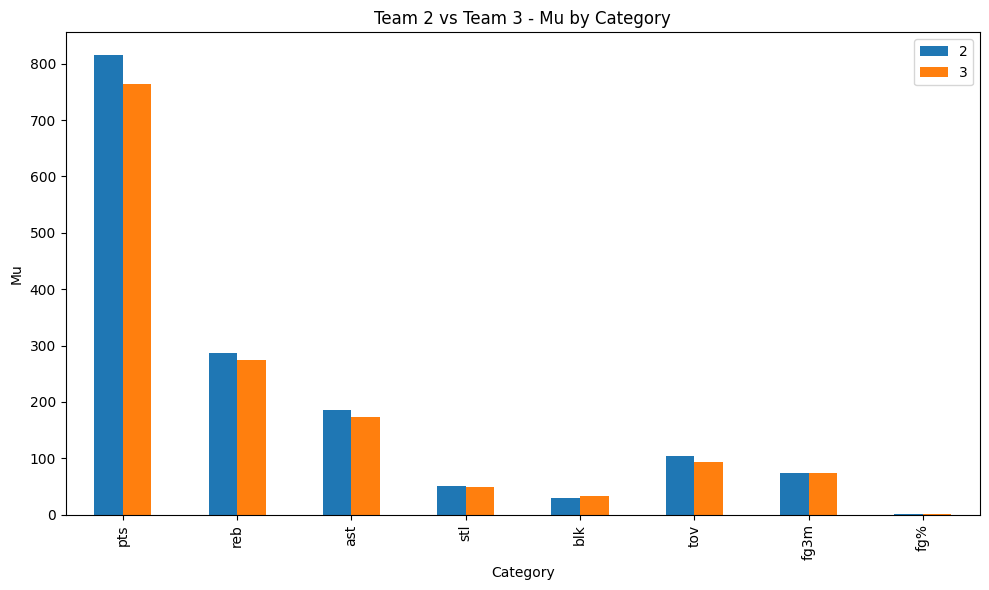

In [ ]:
plot_categories = ["pts", "reb", "ast", "stl", "blk", "tov", "fg3m", "fg%", "fg%"]

df_mu = pd.DataFrame({
    2: {cat: stats[2][cat]["mu"] for cat in plot_categories},
    3: {cat: stats[3][cat]["mu"] for cat in plot_categories},
})

ax = df_mu.plot(kind="bar", figsize=(10, 6))
ax.set_xlabel("Category")
ax.set_ylabel("Mu")
ax.set_title("Team 2 vs Team 3 - Mu by Category")
plt.tight_layout()

In [ ]:
stats

{3: {'pts': {'mu': 764.7000026702881, 'var': 2041.528611701072},
  'reb': {'mu': 274.5, 'var': 378.44679787163307},
  'ast': {'mu': 172.89999902248383, 'var': 204.44544396300674},
  'stl': {'mu': 49.09999978542328, 'var': 48.25317694683423},
  'blk': {'mu': 33.8000006377697, 'var': 33.45865840057059},
  'tov': {'mu': 93.6000007390976, 'var': 90.76101108864127},
  'fg3m': {'mu': 73.79999935626984, 'var': 85.98270212332277},
  'fga': {'mu': 565.2217761895125, 'var': 658.920367024467},
  'fgm': {'mu': 273.0355975385609, 'var': 292.23927904012186},
  'fta': {'mu': 178.88729439769241, 'var': 386.85340684103653},
  'ftm': {'mu': 139.15657181659358, 'var': 278.2484094225641},
  'ft%': {'mu': 0.7779008133871617},
  'fg%': {'mu': 0.483059232747988}},
 2: {'pts': {'mu': 814.9000039100647, 'var': 2281.555497302243},
  'reb': {'mu': 286.30000257492065, 'var': 459.3088939331722},
  'ast': {'mu': 185.89999902248383, 'var': 287.6338295189056},
  'stl': {'mu': 51.100000232458115, 'var': 57.66230340753

In [ ]:
def get_win_prob(mu1, var1, mu2, var2, lower_is_better=False):
    combined_sd = np.sqrt(var1 + var2)
    z = (mu1 - mu2) / combined_sd
    if lower_is_better:
        z = -z
    return norm.cdf(z)

# Data for Percentages
# We use 'mu' for p and 'fga/fta' for n to derive the variance
for pct_type, att_type in [('fg%', 'fga'), ('ft%', 'fta')]:
    for p_id in [2, 3]:
        p = stats[p_id][pct_type]['mu']
        n = stats[p_id][att_type]['mu']
        # Calculate variance of the proportion: p(1-p)/n
        stats[p_id][pct_type]['var'] = (p * (1 - p)) / n

# Compare them
categories = ['pts', 'reb', 'ast', 'stl', 'blk', 'tov', 'fg3m', 'fg%', 'ft%']

print(f"{'Category':<10} | {'P3 Win Prob':<12}")
print("-" * 25)

for cat in categories:
    p3_mu, p3_var = stats[3][cat]['mu'], stats[3][cat]['var']
    p2_mu, p2_var = stats[2][cat]['mu'], stats[2][cat]['var']
    
    prob = get_win_prob(p3_mu, p3_var, p2_mu, p2_var, lower_is_better=(cat == 'tov'))
    print(f"{cat:<10} | {prob:.2%}")

Category   | P3 Win Prob 
-------------------------
pts        | 22.26%
reb        | 34.18%
ast        | 27.89%
stl        | 42.30%
blk        | 72.93%
tov        | 77.35%
fg3m       | 49.69%
fg%        | 51.52%
ft%        | 19.04%
